# Image Spatter — adım adım ELA

**Burada ne yapıyoruz?** Bir fotoğrafa küçük bir parça ekleyip JPEG sıkıştırma farklarında bu parçanın nasıl göründüğüne bakıyoruz.

ELA'nın fikri şu: **Görüntüyü tekrar JPEG olarak kaydet. Önceki ve sonraki piksel değerlerini karşılaştır.**

Hücreleri yukarıdan aşağıya çalıştır. İlk örneği fonksiyon kullanmadan yapacağız; sonra aynı işlemi tekrar kullanmak için bir fonksiyona koyacağız.

Parlak bir ELA bölgesi, o bölgede daha büyük sıkıştırma farkı olduğunu gösterir. Tek başına “burası sahte” anlamına gelmez.

English: ELA means Error Level Analysis. We compare an input image with a JPEG-recompressed version and inspect the pixel differences.


## ELA nedir? / What is ELA?

**ELA = Error Level Analysis / Hata Seviyesi Analizi.** JPEG yeniden kaydı bazı piksel değerlerini değiştirir. Bu notebook, giriş görüntüsüyle yeniden sıkıştırılmış görüntünün mutlak farkını gösterir.

```text
Input / Girdi ──JPEG quality Q──> Recompressed / Yeniden sıkıştırılmış
       └────────── absolute difference / mutlak fark ──────────┘
                              ↓
                   ELA map / Fark haritası
```

Bir pikselin üç kanalındaki farklar `[3, 6, 9]` ise haritadaki değeri `(3 + 6 + 9) / 3 = 6` olur. Kodda bunun karşılığı `absdiff(...).mean(axis=2)`.

**Reading the map / Haritayı okuma:** Parlaklık daha büyük piksel farkıdır. Farklı sıkıştırma geçmişleri bazı bölgeleri farklı gösterebilir; düzenlenmiş bir bölge çevresinden daha açık veya daha koyu da görünebilir. Sonuç tek başına gerçek/sahte kararı vermez. [Forensically — ELA explanation](https://29a.ch/photo-forensics/#error-level-analysis).

**Quality vs display / Kalite ve görünüm:** JPEG quality hesaplanan farkı değiştirir. Display max ve overlay opacity yalnızca haritanın görünümünü değiştirir. Bir JPEG kalite sayısı, görüntünün “gerçek olma yüzdesi” değildir.

English: Recompress, subtract, then inspect. This notebook averages absolute channel differences; it does not output a forgery probability.


## 1. Kütüphaneleri aç

- `cv2`: görüntü okuma, kaydetme ve fark alma.
- `numpy`: görüntüyü oluşturan sayı dizileriyle çalışma.
- `matplotlib`: görüntüleri ekranda gösterme.
- `Path`: dosya ve klasör yollarını yazma.
- `perf_counter`: işlemin ne kadar sürdüğünü ölçme.

English: Imports provide image I/O, arrays, plotting, paths and timing.


In [100]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter


## 2. Görüntüyü oku

Notebook'u **Image_Processing_Project klasöründe** aç.

`data` içinde örnek görüntümüz var. Ürettiğimiz dosyalar `outputs` içine gidecek.
`exist_ok=True`, klasör zaten varsa hata verme demek.

`str(...)`, dosya yolunu OpenCV için yazıya çevirir.

English: Read the sample from data/ and save demo outputs in outputs/. Run the notebook from the project folder.


In [101]:
data_dir = Path("data")
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

source_img = cv2.imread(str(data_dir / "astronaut.png"))

if source_img is None:
    raise FileNotFoundError("data/astronaut.png bulunamadı. Notebook'u proje klasöründe aç.")

print("Görüntü boyutu:", source_img.shape)


Görüntü boyutu: (512, 512, 3)


`shape` sonucu `(512, 512, 3)`: 512 satır, 512 sütun ve 3 renk kanalı.

OpenCV renkleri **BGR** sırasında okur. Matplotlib **RGB** bekler. Bu yüzden ekranda gösterirken `cv2.cvtColor` kullanacağız.

English: shape is (height, width, channels). OpenCV uses BGR; Matplotlib displays RGB.


## 3. Kontrollü bir düzenleme yap

### 3.1. JPEG bir arka plan hazırla

PNG kaynağımızı önce JPEG kalite **75** ile kaydedip tekrar okuyoruz.
JPEG bazı bilgileri kaybettiği için okuduğumuz piksel değerleri kaynaktan biraz farklı olacak.

Bu adımı, arka planla birazdan ekleyeceğimiz parçanın sıkıştırma geçmişleri farklı olsun diye yapıyoruz.

English: Save a quality-75 JPEG background to create a known compression history.


In [102]:
base_path = output_dir / "base_q75.jpg"

cv2.imwrite(str(base_path), source_img, [cv2.IMWRITE_JPEG_QUALITY, 75])
base_img = cv2.imread(str(base_path))


### 3.2. Bir parçayı başka yere yapıştır

Görüntüden parça seçerken yazım sırası:

`görüntü[başlangıç_satırı:bitiş_satırı, başlangıç_sütunu:bitiş_sütunu]`

Aşağıdaki ilk aralık armayı seçer: **340–419. satırlar, 130–209. sütunlar**.
Her iki aralık da 80 piksel uzunluğunda; yani parça **80 × 80**.

`.copy()` kullanarak arka planın ayrı bir kopyasını düzenliyoruz.

English: Array slicing selects rows first, then columns. The stop index is excluded. copy() creates an independent image.


In [103]:
patch = source_img[340:420, 130:210].copy()

edited_img = base_img.copy()
edited_img[40:120, 390:470] = patch


### 3.3. İki görüntüyü de aynı son kaliteyle kaydet

**Kontrol:** Parça eklenmemiş görüntü.  
**Düzenlenmiş:** Sağ üstüne arma eklediğimiz görüntü.

İkisini de kalite **95** ile kaydediyoruz. Böylece son kaydetme ayarları aynı oluyor.
ELA hesabında bu dosyalardan geri okuduğumuz görüntüleri kullanacağız.

English: Both samples receive the same final JPEG quality, 95. The control contains no added patch.


In [104]:
original_path = output_dir / "control.jpg"
edited_path = output_dir / "edited.jpg"

cv2.imwrite(str(original_path), base_img, [cv2.IMWRITE_JPEG_QUALITY, 95])
cv2.imwrite(str(edited_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, 95])

original_img = cv2.imread(str(original_path))
edited_img = cv2.imread(str(edited_path))


### 3.4. Düzenlediğimiz yeri göster

Bir **maske**, hangi piksellerle ilgilendiğimizi gösteren ayrı bir görüntüdür.

Burada siyah **0**, beyaz **255**. Sadece parçayı eklediğimiz alanı beyaz yapıyoruz.
Bu alanı algoritma bulmadı; parçayı biz eklediğimiz için yerini biliyoruz.

`shape[:2]` sadece satır ve sütun sayısını alır. `zeros` bu boyutta sıfırlardan oluşan bir görüntü oluşturur. `uint8`, 0–255 arasındaki tam sayıları tutan veri tipidir.

English: The mask records the edit we made. It is ground truth for this demo, not a detected region.


In [105]:
known_mask = np.zeros(edited_img.shape[:2], dtype=np.uint8)
known_mask[40:120, 390:470] = 255

cv2.imwrite(str(output_dir / "known_mask.png"), known_mask)


True

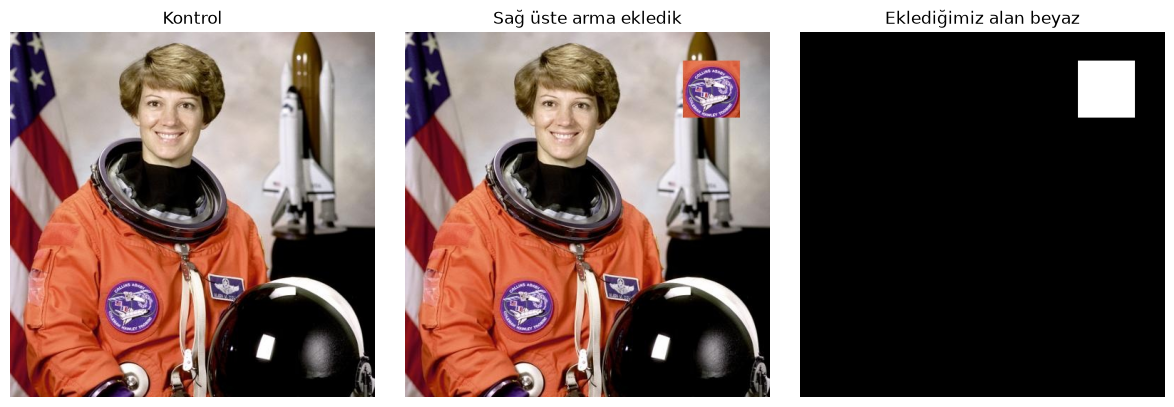

In [106]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Kontrol")
plt.axis(False)

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Sağ üste arma ekledik")
plt.axis(False)

plt.subplot(1, 3, 3)
plt.imshow(known_mask, cmap="gray", vmin=0, vmax=255)
plt.title("Eklediğimiz alan beyaz")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "controlled_edit.png")
plt.show()


## 4. ELA hesabını adım adım yap

### 4.1. Düzenlenmiş görüntüyü tekrar JPEG olarak kaydet

Bu kez kalite **90** kullanıyoruz.
`recompressed_img`, bu yeni JPEG dosyasından geri okuduğumuz görüntü.

Henüz fark hesabı yapmadık; sadece karşılaştıracağımız ikinci görüntüyü hazırladık.

English: Recompression creates the second image used by ELA. Here the JPEG quality is 90.


In [107]:
jpeg_quality = 90
recompressed_path = output_dir / "recompressed.jpg"

cv2.imwrite(str(recompressed_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_img = cv2.imread(str(recompressed_path))


### 4.2. İki görüntünün farkını al

`edited_img`: yeniden kaydetmeden önceki görüntü.  
`recompressed_img`: yeniden kaydettikten sonraki görüntü.

`absdiff`, aynı konumdaki piksel değerlerinin **mutlak farkını** alır.

Örnek: 120 ile 115 arasındaki fark **5**. Aynı kalan bir değerin farkı **0**.
Doğrudan `uint8` çıkarma işlemi yerine bunu kullanıyoruz; negatif farklarda taşma olmasını önlüyor.

English: absdiff computes absolute per-channel pixel differences and avoids unsigned subtraction wraparound.


In [108]:
difference_img = cv2.absdiff(edited_img, recompressed_img)

print("Fark görüntüsünün boyutu:", difference_img.shape)


Fark görüntüsünün boyutu: (512, 512, 3)


### 4.3. Üç renk farkını tek sayıya indir

Her pikselde B, G ve R için üç ayrı fark var.
`mean(axis=2)`, **renk kanallarının ortalamasını** alır.

Örnek: bir pikselde farklar `[3, 6, 9]` ise sonuç `(3 + 6 + 9) / 3 = 6`.

Böylece 3 kanallı fark görüntüsü, tek bir **ELA haritasına** dönüşür.

English: mean(axis=2) averages the three channel differences into one error value per pixel.


In [109]:
edited_ela = difference_img.mean(axis=2)

print("ELA haritasının boyutu:", edited_ela.shape)
print("Görüntünün ortalama farkı:", round(edited_ela.mean(), 3))


ELA haritasının boyutu: (512, 512)
Görüntünün ortalama farkı: 0.801


### 4.4. Aynı işlemi kontrol görüntüsüne de uygula

Yine aynı üç adım: **kaydet → oku → farkı hesapla**.
Kaliteyi değiştirmiyoruz; iki görüntüyü aynı ayarla karşılaştıracağız.

English: Apply the same recompression quality to the control for a consistent comparison.


In [110]:
cv2.imwrite(str(recompressed_path), original_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_original = cv2.imread(str(recompressed_path))

original_difference = cv2.absdiff(original_img, recompressed_original)
original_ela = original_difference.mean(axis=2)


## 5. Sonuçları yan yana göster

`plt.subplot(2, 2, 1)`: **2 satır, 2 sütun**, birinci kutuya çiz.

ELA haritalarında aynı renk ölçeğini kullanıyoruz: **0–20**.
Koyu renk küçük farkı, açık renk büyük farkı gösterir.
20 üzerindeki değerler de en açık renkte görünür; bu sınır sadece çizim içindir.

English: Use one fixed color scale for both maps. The display limit clips colors, not the raw measurements.


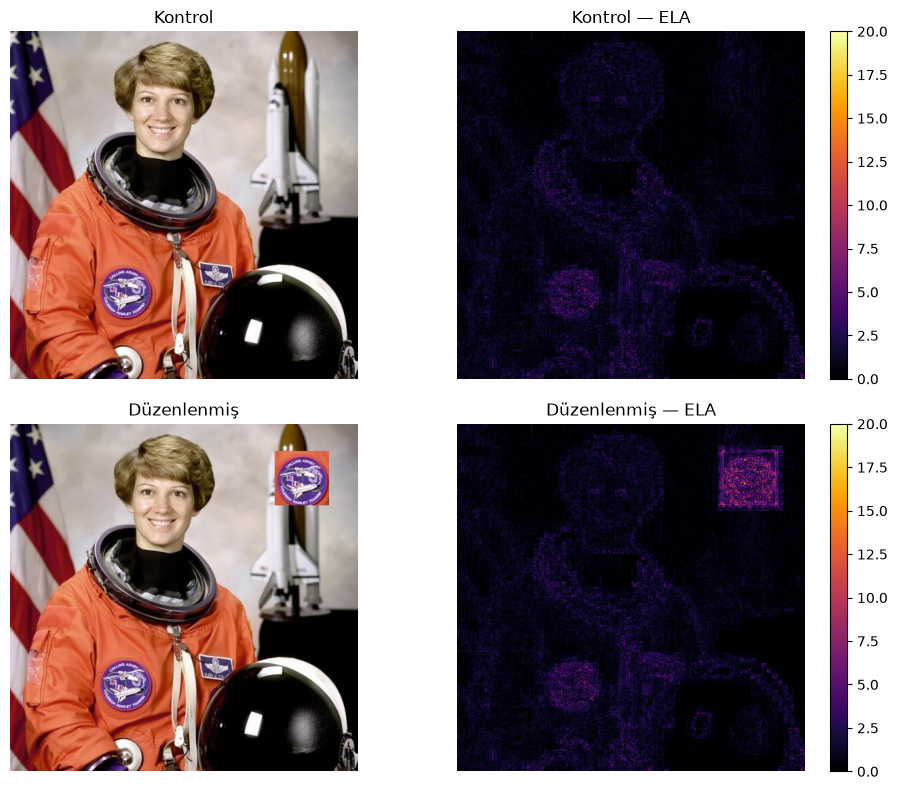

In [111]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Kontrol")
plt.axis(False)

plt.subplot(2, 2, 2)
plt.imshow(original_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Kontrol — ELA")
plt.axis(False)

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Düzenlenmiş")
plt.axis(False)

plt.subplot(2, 2, 4)
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Düzenlenmiş — ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_comparison.png")
plt.show()


### ELA'yı görüntünün üstüne koy

İlk `imshow` fotoğrafı çizer. İkinci `imshow`, ELA haritasını onun üstüne çizer.
`alpha=0.5`, üstteki haritanın yarı saydam görünmesini sağlar.

English: The overlay draws the ELA map on top of the input. alpha controls its opacity.


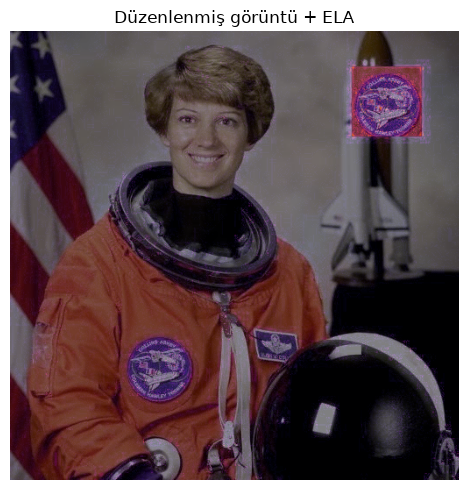

In [112]:
plt.figure(figsize=(5, 5))

plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20, alpha=0.5)
plt.title("Düzenlenmiş görüntü + ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_overlay.png")
plt.show()


### Eklediğimiz alandaki farkı sayıyla karşılaştır

İki haritada da **aynı koordinatları** seçip ortalama farkı hesaplıyoruz.

Buradaki sayılar piksel farklarının ortalamasıdır. **Yüzde veya sahte olma olasılığı değildir.**
JPEG, parçanın sınırının çevresindeki pikselleri de etkileyebilir.

`round(değer, 3)`, ekrana yazılan sayıyı üç ondalık basamağa yuvarlar.

English: Compare mean error in the same coordinates. These numbers are pixel differences, not probabilities.


In [113]:
original_region = original_ela[40:120, 390:470]
edited_region = edited_ela[40:120, 390:470]

print("Kontrolde bu alanın ortalama farkı:", round(original_region.mean(), 3))
print("Düzenlemeden sonra ortalama fark:", round(edited_region.mean(), 3))


Kontrolde bu alanın ortalama farkı: 0.556
Düzenlemeden sonra ortalama fark: 4.475


## 6. Aynı hesabı tekrar kullan: fonksiyon

Buraya kadar ELA'yı tek tek yaptık. Şimdi **aynı satırları** bir fonksiyonun içine koyuyoruz.

`calculate_ela(img, quality)`:
- `img`: inceleyeceğimiz görüntü.
- `quality`: yeniden kaydederken kullanılacak JPEG kalitesi.
- `return`: hesaplanan ELA haritasını bize geri verir.

`recompressed.jpg` tekrar kullanılan bir çalışma dosyasıdır; her çağrıda üzerine yazılır.

English: A function groups the same steps for reuse. The original demo uses a scratch JPEG on disk.


In [114]:
def calculate_ela(img, quality):
    if not isinstance(quality, int) or not 1 <= quality <= 100:
        raise ValueError("JPEG kalitesi 1 ile 100 arasında bir tam sayı olmalı.")

    saved = cv2.imwrite(str(recompressed_path), img, [cv2.IMWRITE_JPEG_QUALITY, quality])
    if not saved:
        raise OSError("JPEG dosyası kaydedilemedi.")

    recompressed_img = cv2.imread(str(recompressed_path))
    difference_img = cv2.absdiff(img, recompressed_img)
    ela_map = difference_img.mean(axis=2)

    return ela_map


### Süreyi ölç

Başlangıç ve bitiş saatinin farkını alıyoruz.
Sonuç saniye cinsinden geldiği için **1000** ile çarparak milisaniyeye çeviriyoruz.

Bu sürüm JPEG'i diske yazıp okuduğu için ölçülen süreye **dosya yazma ve okuma da dahildir**.

English: This disk-based demo timing includes JPEG file writing and reading.


In [115]:
start_time = perf_counter()

test_ela = calculate_ela(edited_img, 90)

elapsed_ms = (perf_counter() - start_time) * 1000
print("ELA işlem süresi (ms):", round(elapsed_ms, 2))


ELA işlem süresi (ms): 3.7


## 7. Kaliteyi iyice düşürürsek ne olur? / Low-quality comparison

Bu kez **5, 10, 20, 40, 60, 80, 90 ve 95** değerlerini deniyoruz. Böylece yalnızca yüksek kaliteli JPEG'lere bakmakla kalmıyoruz; çok düşük kaliteye indiğimizde ne olduğunu da görebiliyoruz.

- **5, 10, 20:** bu demodaki çok düşük kalite denemeleri.
- **40, 60:** aradaki değişimi görmek için.
- **80, 90, 95:** yüksek kaliteyle karşılaştırmak için.

`for`, her kaliteyi sırayla dener. Her hesap aynı giriş görüntüsünden başlar; önceki JPEG sonucunu bir sonraki denemeye vermiyoruz.

Düşük kalitede fotoğrafın normal bölgelerinde de büyük farklar oluşabilir. Haritanın daha parlak çıkmasını “daha iyi tespit” diye yorumlamayacağız. Bütün haritalarda aynı 0–20 renk ölçeğini koruyoruz; 20 üzerindeki farklar aynı en açık renkte görünür, ölçümlerse ham sayılardan alınır.

English: Include strong JPEG compression to inspect parameter sensitivity. More visible error is not a forgery confidence score.


In [ ]:
qualities = [5, 10, 20, 40, 60, 80, 90, 95]
original_maps = []
edited_maps = []
quality_results = []

for quality in qualities:
    start_time = perf_counter()
    original_map = calculate_ela(original_img, quality)
    original_time = (perf_counter() - start_time) * 1000

    start_time = perf_counter()
    edited_map = calculate_ela(edited_img, quality)
    edited_time = (perf_counter() - start_time) * 1000

    original_mean = original_map[40:120, 390:470].mean()
    edited_mean = edited_map[40:120, 390:470].mean()

    original_maps.append(original_map)
    edited_maps.append(edited_map)
    quality_results.append([quality, original_mean, edited_mean, original_time, edited_time])

    print("JPEG kalitesi:", quality)
    print("  Kontrol alanındaki ortalama fark:", round(original_mean, 3))
    print("  Eklenen alandaki ortalama fark:", round(edited_mean, 3))


### Bütün kalite aralığını birlikte görelim

Grafiğin **üst yarısı kontrol**, **alt yarısı düzenlenmiş** görüntü. Her satırda en fazla dört harita var; böylece düşük kalite değerleri de okunabilir boyutta kalıyor.

`columns` sütun sayısı, `rows` ise her görüntü için gereken satır sayısı. `control_slots`, üst yarının kapladığı kutu sayısı; alt yarıdaki haritaları onun ardından çiziyoruz.

Önce aynı kalite değerinde kontrol ve düzenlenmiş örneği karşılaştır. Sonra kaliteyi 95'ten 5'e doğru düşürdüğümüzde farkların fotoğrafın geneline nasıl yayıldığına bak. Renk ölçeği bütün kutularda aynı.


In [ ]:
# Each row has at most 4 maps / Her satırda en fazla 4 harita.
columns = min(4, len(qualities))
rows = (len(qualities) + columns - 1) // columns
control_slots = rows * columns

plt.figure(figsize=(3 * columns, 6 * rows))

for i in range(len(qualities)):
    # Upper half / Üst yarı: kontrol görüntüsü.
    plt.subplot(2 * rows, columns, i + 1)
    plt.imshow(original_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Kontrol — kalite {qualities[i]}")
    plt.axis(False)

    # Lower half / Alt yarı: düzenlenmiş görüntü.
    plt.subplot(2 * rows, columns, control_slots + i + 1)
    plt.imshow(edited_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Düzenlenmiş — kalite {qualities[i]}")
    plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "quality_comparison.png")
plt.show()


### Ölçümleri dosyaya kaydet

`quality_results` listesindeki her satırda sırasıyla şunlar var:

**JPEG kalitesi, kontrol bölgesinin ortalama farkı, düzenlenmiş bölgenin ortalama farkı, kontrol süresi, düzenlenmiş görüntünün süresi.**

CSV, bu sayıları Excel gibi bir programda da açabilmemizi sağlar.

English: Save numeric measurements as CSV for use in a spreadsheet.


In [118]:
np.savetxt(
    output_dir / "quality_comparison.csv",
    quality_results,
    delimiter=",",
    header="jpeg_quality,control_region_mean,edited_region_mean,control_time_ms,edited_time_ms",
    comments="",
    fmt="%.3f"
)


## Ne gördük?

- JPEG'i tekrar kaydetmek piksel değerlerinde fark oluşturuyor; ELA bu farkı gösteriyor.
- Bu deneyde farklı sıkıştırma geçmişi olan bir parça ekledik. Bu, ELA'yı göstermek için seçilmiş bir örnek.
- Kontrol görüntüsündeki arma, kenarlar ve dokular da fark üretebiliyor.
- Kullanılan JPEG kalitesi sonucu değiştiriyor. Her düzenleme görünür olmak zorunda değil.
- Tek örnekten genel tespit başarısı veya “gerçek / sahte” kararı çıkaramayız.

İlk demo burada tamamlandı. Aşağıdaki bölüm başka bir yerel görüntüyü denemek için.

English: This controlled example demonstrates a compression difference. A single example does not establish detection accuracy.


## 8. Custom image / Kendi görüntünü incele

Bu bölüm **üstteki demo çalışmadan da** kullanılabilir. Buradan başlayarak custom hücrelerini sırayla çalıştır. Ayar değiştirdiğinde bu bölümü baştan çalıştır.

**Workflow / Akış:** dosya yolunu seç → kaliteyi ayarla → input / ELA / overlay karşılaştır → farklı kaliteleri dene → istersen bir bölgeyi yakından incele → çıktıları kaydet.

Başlangıçta projeyle gelen örnek görüntü seçili. Başka dosya için yalnızca `custom_image_path` değerini değiştir. Mutlak yol veya proje klasörüne göre bir yol kullanabilirsin: `"data/astronaut.png"`. `None` seçersen custom analiz atlanır.

English: The custom section is self-contained. Choose a local file and run these cells in order. All image analysis runs locally.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter
from tempfile import mkdtemp
from PIL import Image, ImageOps


### Settings / Değiştireceğin ayarlar

| Setting | Meaning / Anlamı |
|---|---|
| `custom_image_path` | Yerel dosya yolu / local image path |
| `custom_quality` | Seçili ELA için JPEG kalitesi; tam sayı 1–100 |
| `custom_display_max` | Haritada en parlak rengin başladığı fark değeri; daha küçük değer haritayı daha parlak gösterir |
| `custom_overlay_alpha` | Haritanın opaklığı; 0 görünmez, 1 tamamen görünür |
| `custom_qualities` | Karşılaştırılacak JPEG kalite değerleri |
| `custom_roi` | İsteğe bağlı bölge: `(x, y, width, height)`; `None` tüm görüntü |
| `custom_save_outputs` | Sonuçları yerel dosyalara kaydetmek için `True` |

English: Quality changes the analysis. Display max and alpha change only the visualization. For the bundled sample, try ROI `(390, 40, 80, 80)`. Coordinates refer to the displayed, correctly oriented image.


In [ ]:
custom_image_path = "data/astronaut.png"
custom_quality = 80

custom_display_max = 20
custom_overlay_alpha = 0.5
custom_qualities = [5, 10, 20, 40, 60, 80, 90, 95]
custom_roi = None  # Optional region / Bölge: (x, y, width, height)

custom_save_outputs = True
custom_output_root = Path("outputs") / "custom"


### Load image / Görüntüyü aç

Pillow ile dosyanın **gerçek formatını** okuyoruz; sadece `.jpg` uzantısına bakmıyoruz. Telefon fotoğraflarının EXIF yön bilgisini uygular, ardından RGB görüntüyü OpenCV için BGR'ye çeviririz. Piksel boyutlarını küçültmeyiz.

JPEG dışındaki girişlerde de fark hesaplanır. Ancak sonuç, örneğin bir PNG'nin JPEG'e çevrilirken verdiği tepkiyi gösterir; önceki bir JPEG sıkıştırmasının kanıtı olarak yorumlanamaz. Saydam alan varsa beyaz zeminle birleştirilir ve bilgi yazdırılır.

English: Detect the actual image format, apply EXIF orientation, and analyze 8-bit color pixels at full resolution. [Pillow orientation documentation](https://pillow.readthedocs.io/en/stable/reference/ImageOps.html#PIL.ImageOps.exif_transpose).


In [ ]:
# Reset results / Önceki çalıştırmanın sonucunu kullanma.
custom_img = None
custom_ela = None
custom_figure = None
custom_quality_figure = None
custom_roi_figure = None
custom_quality_rows = []
custom_roi_row = []

if custom_image_path is None:
    print("No image selected / custom_image_path değerine dosya yolu yaz.")
else:
    custom_path = Path(custom_image_path).expanduser()
    if not custom_path.is_file():
        raise FileNotFoundError("Image not found / Dosya yolunu kontrol et.")

    with Image.open(custom_path) as image_file:
        custom_format = image_file.format
        oriented_img = ImageOps.exif_transpose(image_file)

        if oriented_img.mode not in ("1", "L", "LA", "P", "RGB", "RGBA", "CMYK", "YCbCr"):
            raise ValueError("Use an 8-bit image / Bu demo için 8-bit JPEG veya PNG kullan.")

        has_alpha = "A" in oriented_img.getbands() or "transparency" in image_file.info
        if has_alpha:
            rgba_img = oriented_img.convert("RGBA")
            white_background = Image.new("RGBA", rgba_img.size, "white")
            oriented_img = Image.alpha_composite(white_background, rgba_img)
            print("Transparency / Saydam alanlar beyaz zeminle birleştirildi.")

        custom_rgb = np.array(oriented_img.convert("RGB"))

    custom_img = cv2.cvtColor(custom_rgb, cv2.COLOR_RGB2BGR)
    print("File / Dosya:", custom_path.name)
    print("Format:", custom_format)
    print("Size / Boyut (height, width, channels):", custom_img.shape)

    if custom_format != "JPEG":
        print("Non-JPEG input / Bu harita, girişin JPEG'e yeniden kodlanma farkını gösterir.")


### ELA function / Farkı hesaplayan fonksiyon

Yine aynı işlem: **JPEG oluştur → geri oku → mutlak fark → renk kanallarının ortalaması**.

Bu bölümde `imencode` JPEG verisini bellekte oluşturur, `imdecode` onu tekrar piksellere çevirir. `imwrite` / `imread` ile öğrendiğimiz JPEG işleminin dosya oluşturmadan yapılan halidir. Giriş dosyasına yazmayız.

English: A JPEG round trip in memory. The returned map contains raw mean absolute channel differences, not normalized probabilities. Custom timing includes encoding, decoding and the difference calculation; it excludes input loading, plotting and exports.


In [ ]:
def calculate_custom_ela(img, quality):
    if type(quality) is not int or not 1 <= quality <= 100:
        raise ValueError("JPEG quality / kalite: 1–100 arasında bir tam sayı olmalı.")

    # Encode / Seçilen kalitede JPEG oluştur.
    success, jpeg_data = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, quality])
    if not success:
        raise RuntimeError("JPEG encoding failed / JPEG oluşturulamadı.")

    # Decode / JPEG verisini tekrar görüntüye çevir.
    recompressed_img = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
    difference_img = cv2.absdiff(img, recompressed_img)

    return difference_img.mean(axis=2)


### Analyze / Analizi çalıştır

**Mean error / Ortalama fark:** bütün piksellerin ortalama ELA değeri.  
**95th percentile / Yüzde 95 eşiği:** piksellerin en az %95'inin fark değerinin eşit veya altında kaldığı seviye.

Bunlar görüntüyü betimleyen sayılardır; **manipülasyon yüzdesi veya güven puanı değildir**. Sayılar ham haritadan hesaplanır, renk ölçeğinden etkilenmez.


In [ ]:
if custom_img is not None:
    if not np.isfinite(custom_display_max) or custom_display_max <= 0:
        raise ValueError("Display max / Görünüm üst sınırı sıfırdan büyük olmalı.")
    if not 0 <= custom_overlay_alpha <= 1:
        raise ValueError("Overlay alpha / Opaklık 0 ile 1 arasında olmalı.")

    start_time = perf_counter()
    custom_ela = calculate_custom_ela(custom_img, custom_quality)
    custom_elapsed_ms = (perf_counter() - start_time) * 1000

    print("JPEG quality / Kalite:", custom_quality)
    print("Mean error / Ortalama fark:", round(custom_ela.mean(), 3))
    print("95th percentile / Yüzde 95 eşiği:", round(np.percentile(custom_ela, 95), 3))
    print("Analysis time / Süre (ms):", round(custom_elapsed_ms, 2))


### Input · ELA · Overlay / Üç görünümü karşılaştır

Solda giriş görüntüsü, ortada ELA, sağda aynı haritanın fotoğraf üzerine bindirilmiş hali var.
`vmin=0` ve `vmax=custom_display_max` ortak renk ölçeğini belirler. Üst sınırdan büyük farklar aynı en parlak renkte görünür. Overlay opaklığı ham farkları değiştirmez.

English: Bright means larger recompression difference at this setting. Compare the map with the input to see whether bright areas follow normal edges or texture. The input is a selected file, not a verified original.


In [ ]:
if custom_ela is not None:
    custom_figure = plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(custom_rgb)
    plt.title("Input / Girdi")
    plt.axis(False)

    plt.subplot(1, 3, 2)
    plt.imshow(custom_ela, cmap="inferno", vmin=0, vmax=custom_display_max)
    plt.colorbar(label="Mean absolute difference / Ortalama mutlak fark")
    plt.title(f"ELA — JPEG quality {custom_quality}")
    plt.axis(False)

    plt.subplot(1, 3, 3)
    plt.imshow(custom_rgb)
    plt.imshow(custom_ela, cmap="inferno", vmin=0, vmax=custom_display_max,
               alpha=custom_overlay_alpha)
    plt.title("Overlay / Üst üste görünüm")
    plt.axis(False)

    plt.tight_layout()
    plt.show()


### Quality comparison / Aynı dosya, farklı kaliteler

Giriş dosyasını her kalite için **baştan** kullanıyoruz. Kalite 70 sonucunu kalite 80 hesabına vermiyoruz. Haritaların renk ölçeği aynı; görüntü başına otomatik normalleştirme yapmıyoruz.

English: Every quality starts from the same decoded input. The comparison shows parameter sensitivity; it does not estimate the file's original JPEG quality.

Düşük kalite aralığı da listede: **5, 10, 20, 40, 60, 80, 90, 95**. Aynı fotoğrafı her ayarda yeniden inceliyoruz. Haritalar en fazla dört sütunla gösterilir. Çok düşük kalite, normal dokularda da fark oluşturabilir; parlaklık tespit başarısı değildir.

English: Low-quality presets are included; all maps keep the same display scale.


In [ ]:
custom_quality_rows = []
custom_quality_figure = None

if custom_ela is not None:
    if not custom_qualities:
        raise ValueError("Quality list / En az bir kalite değeri yaz.")

    columns = min(4, len(custom_qualities))
    rows = (len(custom_qualities) + columns - 1) // columns
    custom_quality_figure = plt.figure(figsize=(3 * columns, 3.5 * rows))

    for i in range(len(custom_qualities)):
        quality = custom_qualities[i]
        start_time = perf_counter()
        quality_map = calculate_custom_ela(custom_img, quality)
        elapsed_ms = (perf_counter() - start_time) * 1000

        mean_error = float(quality_map.mean())
        p95_error = float(np.percentile(quality_map, 95))
        custom_quality_rows.append([quality, mean_error, p95_error, elapsed_ms])

        plt.subplot(rows, columns, i + 1)
        plt.imshow(quality_map, cmap="inferno", vmin=0, vmax=custom_display_max)
        plt.title(f"Quality / Kalite {quality}")
        plt.axis(False)
        print(f"Q={quality}: mean={mean_error:.3f}, P95={p95_error:.3f}, time={elapsed_ms:.2f} ms")

    plt.tight_layout()
    plt.show()


### ROI / İstersen bir bölgeyi yakından incele

**ROI = Region of Interest / İlgi bölgesi.** Ayarlardaki `custom_roi` değerini örneğin `(100, 80, 120, 100)` yap:
- `x=100`: soldan 100 piksel.
- `y=80`: üstten 80 piksel.
- `width=120`, `height=100`: bölgenin genişliği ve yüksekliği.

Yeşil kutu senin seçimin. Tespit sonucu veya bilinen düzenleme maskesi değildir.
**Önce bütün görüntünün ELA'sı hesaplanır, sonra bu haritadan bölge seçilir.** Parçayı ayrıca JPEG'e çevirip sıkıştırma ızgarasını değiştirmiyoruz.

English: Inspect a crop of the existing full-image map. Coordinates refer to the EXIF-oriented input. Keep `None` to skip the crop.


In [ ]:
custom_roi_row = []
custom_roi_figure = None

if custom_ela is not None and custom_roi is not None:
    if not isinstance(custom_roi, (tuple, list)) or len(custom_roi) != 4:
        raise ValueError("ROI: (x, y, width, height) şeklinde dört sayı yaz.")
    if not all(type(value) is int for value in custom_roi):
        raise ValueError("ROI coordinates / Bölge koordinatları tam sayı olmalı.")

    x, y, width, height = custom_roi
    image_height, image_width = custom_img.shape[:2]
    if x < 0 or y < 0 or width <= 0 or height <= 0:
        raise ValueError("ROI başlangıcı negatif olamaz; genişlik ve yükseklik pozitif olmalı.")
    if x + width > image_width or y + height > image_height:
        raise ValueError("ROI is outside the image / Bölge görüntünün dışına taşıyor.")

    roi_rgb = custom_rgb[y:y + height, x:x + width]
    roi_ela = custom_ela[y:y + height, x:x + width]
    custom_roi_row = [x, y, width, height, float(roi_ela.mean())]

    roi_preview = custom_rgb.copy()
    cv2.rectangle(roi_preview, (x, y), (x + width - 1, y + height - 1), (0, 255, 0), 2)
    custom_roi_figure = plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(roi_preview)
    plt.title("Selected region / Seçilen alan")
    plt.axis(False)

    plt.subplot(1, 3, 2)
    plt.imshow(roi_rgb)
    plt.title("Crop / Yakın görünüm")
    plt.axis(False)

    plt.subplot(1, 3, 3)
    plt.imshow(roi_ela, cmap="inferno", vmin=0, vmax=custom_display_max)
    plt.colorbar()
    plt.title("ROI — ELA")
    plt.axis(False)

    plt.tight_layout()
    plt.show()
    print("ROI mean error / Bölgenin ortalama farkı:", round(roi_ela.mean(), 3))


### Export / Sonuçları yerel kaydet

Her çalıştırma `outputs/custom/<dosya_adı>/` içinde ayrı bir klasör oluşturur.

- `comparison.png`: input, ELA ve overlay.
- `ela_heatmap.png`: seçili renk ölçeğiyle çizilmiş harita.
- `ela_raw.npy`: renk ölçeği uygulanmamış **ham piksel farkları**.
- `quality_comparison.png` ve `.csv`: farklı kalitelerdeki harita ve ölçümler.
- `roi.png` ve `roi.csv`: bölge seçtiysen yakın görünüm ve ortalaması.
- `summary.txt`: dosya adı, format, boyut ve analiz ayarları.

English: Export creates a fresh result folder. PNG files are visualizations; use the NumPy array for raw measurements. The input file is read-only, and EXIF contents are not included in the summary.


In [ ]:
if custom_ela is not None and custom_save_outputs:
    image_output_dir = custom_output_root / custom_path.stem
    image_output_dir.mkdir(parents=True, exist_ok=True)
    # mkdtemp creates a new folder / Her çalıştırmada ayrı klasör.
    custom_run_dir = Path(mkdtemp(prefix=f"q{custom_quality}_", dir=image_output_dir))

    custom_figure.savefig(custom_run_dir / "comparison.png", dpi=120)
    plt.imsave(custom_run_dir / "ela_heatmap.png", custom_ela,
               cmap="inferno", vmin=0, vmax=custom_display_max)
    np.save(custom_run_dir / "ela_raw.npy", custom_ela)

    if custom_quality_figure is not None:
        custom_quality_figure.savefig(custom_run_dir / "quality_comparison.png", dpi=120)
        np.savetxt(custom_run_dir / "quality_comparison.csv", custom_quality_rows,
                   delimiter=",", fmt="%.4f", comments="",
                   header="jpeg_quality,mean_error,p95_error,analysis_time_ms")

    if custom_roi_figure is not None:
        custom_roi_figure.savefig(custom_run_dir / "roi.png", dpi=120)
        np.savetxt(custom_run_dir / "roi.csv", [custom_roi_row], delimiter=",",
                   fmt="%.4f", comments="", header="x,y,width,height,mean_error")

    summary = (
        f"Input filename: {custom_path.name}\nFormat: {custom_format}\n"
        f"Size (height, width): {custom_img.shape[:2]}\nJPEG quality: {custom_quality}\n"
        f"Display max: {custom_display_max}\nOverlay alpha: {custom_overlay_alpha}\n"
        f"Mean absolute error: {custom_ela.mean():.4f}\n"
        f"Analysis time, memory JPEG round trip (ms): {custom_elapsed_ms:.2f}\n"
        "ELA values are pixel differences, not forgery probabilities.\n"
    )
    (custom_run_dir / "summary.txt").write_text(summary, encoding="utf-8")
    print("Saved / Kaydedildi:", custom_run_dir)


### Interpretation / Nasıl yorumlayacağız?

1. Önce giriş görüntüsüne bak: haritadaki yüksek farklar yazı, kenar veya dokuya mı denk geliyor?
2. Farklı JPEG kalitelerinde bölgenin davranışını karşılaştır. Tek bir ayar, dosyanın geçmişini açıklamaz.
3. Overlay ve ROI ile konumu incele. Seçtiğin kutu bir tespit değildir.
4. Mean / P95 değerlerini ölçüm olarak raporla; bir doğruluk veya sahte olma yüzdesi üretmiyoruz.

English: Use ELA as a visual inspection aid. A bright patch is a reason to inspect context, and a dark map does not establish authenticity. The custom input has no ground-truth edit mask, so detection accuracy cannot be calculated here.


## 9. İrem örneklerini karşılaştır

Bu hücreyi proje klasöründe tek başına çalıştırabilirsin. Yalnızca belirli dosyaları incelemek için `example_filenames` listesini düzenle.

İrem'in deneyindeki gibi her görüntüyü bellekte JPEG kalite 80 ile yeniden sıkıştırıyoruz. Solda giriş görüntüsü, sağda 0–20 ortak renk ölçeğiyle ELA haritası var. Her grafiğin bir kopyası `outputs/irem_examples/` klasörüne yazılır.

AVIF ve WebP haritaları girdinin JPEG'e dönüşüm farkını gösterir. Ortalama ELA farkı piksel değerleri üzerinden hesaplanır.


In [ ]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

example_dir = Path("data/iremimg")
example_output_dir = Path("outputs/irem_examples")
example_filenames = [
    "596fa37556152c22b45c6eb2.avif",
    "596fa37556152c22b45c6eb3.avif",
    "kh-composite-man-2.webp",
    "nintchdbpict000339476175.webp",
    "maxresdefault.jpg",
    "plus-size-celebrity-photoshopped-thinner-project-harpoon-thinnerbeauty-13.jpg",
]
example_quality = 80

if not example_dir.is_dir():
    raise FileNotFoundError("Notebook'u proje klasöründe çalıştır. data/iremimg bulunamadı.")

example_output_dir.mkdir(parents=True, exist_ok=True)
for filename in example_filenames:
    image_path = example_dir / filename
    # Dosya yolu Unicode karakterler içerebilir.
    image = cv2.imdecode(np.frombuffer(image_path.read_bytes(), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        # OpenCV'nin bazı derlemelerinde AVIF desteği yok.
        with Image.open(image_path) as source:
            image = cv2.cvtColor(np.asarray(source.convert("RGB")), cv2.COLOR_RGB2BGR)

    saved, jpeg_data = cv2.imencode(".jpg", image, [cv2.IMWRITE_JPEG_QUALITY, example_quality])
    if not saved:
        raise OSError(f"JPEG dönüşümü başarısız: {filename}")
    recompressed = cv2.imdecode(jpeg_data, cv2.IMREAD_COLOR)
    if recompressed is None:
        raise OSError(f"Yeniden kaydedilen JPEG okunamadı: {filename}")
    ela = cv2.absdiff(image, recompressed).mean(axis=2)

    figure, (input_ax, ela_ax) = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
    input_ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    input_ax.set_title(filename, fontsize=8)
    input_ax.axis("off")
    heatmap = ela_ax.imshow(ela, cmap="inferno", vmin=0, vmax=20)
    ela_ax.set_title(f"ELA — JPEG kalite {example_quality}")
    ela_ax.axis("off")
    figure.colorbar(heatmap, ax=ela_ax, label="Ortalama piksel farkı")

    result_path = example_output_dir / f"{filename}_ela.png"
    figure.savefig(result_path)
    plt.show()
    plt.close(figure)

    print("Dosya:", filename)
    print("Görüntü boyutu:", image.shape)
    print("Ortalama ELA farkı:", round(float(ela.mean()), 3))
    print("Kaydedilen sonuç:", result_path)
